# Group Project - Safe routes home at night 

**DS105A Group Project – Data for Data Science (Autumn Term 2025/2026)**

<div style="font-family: system-ui; padding: 20px 30px 20px 20px; background-color: #FFFFFF; border-left: 8px solid #ED9255; border-radius: 8px; box-shadow: 0 4px 12px rgba(0, 0, 0, 0.1);max-width:600px;color:#212121;">

**Group Notebook**
- 👤 Team Name: CtrlAltElite
- 🎯 Purpose: NB03 will be used to create all of our data visualisations that will display safe routes home. 
</div>

## Data Visualisation Pipeline

1. Understand the data 
   - Do some quick checks of the database, so I can see what I am working with
2. Create a scoring system
   - Create an arbitrary scoring system that looks at number of crimes, distance and time
   - Apply weightings to each crime, a more severe crime has a higher weighting, thus more dangerous 
   - Create an overall scoring system that considers all metrics 
   - Output a score for each route 
3. Test the usability of the scoring system
   - Create tables that show all the route data as well as the scoring metrics 
4. Create plots and maps
   - ss

In [7]:
import sqlite3
import pandas as pd
import numpy as np
from pathlib import Path
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

## Step 1 - Understand the Database


In [8]:
DB_PATH = Path("data/processed/nightclub_safety.db")
conn = sqlite3.connect(str(DB_PATH))

# List all tables
tables = pd.read_sql_query(
    "SELECT name FROM sqlite_master WHERE type='table';",
    conn
)

print("Tables in database:")
display(tables)

# Inspect each table 
for table in tables["name"]:
    print(f"TABLE: {table}")

    # schema
    schema = pd.read_sql_query(f"PRAGMA table_info({table});", conn)
    print("\nColumns & types:")
    display(schema[["name", "type"]])

    # row count
    count = pd.read_sql_query(f"SELECT COUNT(*) AS rows FROM {table};", conn)
    print("\nNumber of rows:")
    display(count)

    # preview data
    preview = pd.read_sql_query(f"SELECT * FROM {table} LIMIT 5;", conn)
    print("\nExample rows:")
    display(preview)

conn.close()


Tables in database:


,name
0,areas
1,sqlite_sequence
2,clubs
3,destinations
4,routes
5,crimes
6,route_crimes


TABLE: areas

Columns & types:


,name,type
0,area_id,INTEGER
1,name,TEXT



Number of rows:


,rows
0,3


... (34 outputs left out)


Number of rows:


,rows
0,4317



Example rows:


,route_id,crime_id
0,4,1
1,4,2
2,4,3
3,4,4
4,4,5


In [9]:
conn = sqlite3.connect("data/processed/nightclub_safety.db")

df = pd.read_sql_query(
    "SELECT DISTINCT category FROM crimes",
    conn
)

conn.close()
display(df)

,category
0,violent-crime
1,public-order
2,anti-social-behaviour


### What have I found and what I intend to use 

- The different types of crimes committed, this is very useful as I can place a weighting on the different types of crimes, thus more serious crimes will further decrease the safety score than if it was a less serious crime. 
- I also will use simple measures such as distance and time, but these will need to be specified by number of crimes along the routes. This will prevent a 100m walk with 1 crime being viewed as safer than a 1km walk with 1 crime.  

## Step 2 - Create a Scoring System 


In [10]:
DB_PATH = Path("data/processed/nightclub_safety.db")
assert DB_PATH.exists(), f"DB not found: {DB_PATH.resolve()}"

conn = sqlite3.connect(str(DB_PATH))

# Extract data from database 
query = """
SELECT
    a.name AS area,
    c.club_id,
    c.displayName AS club_name,
    d.destination_id,
    d.displayName AS destination_name,
    r.route_id,
    r.distanceMeters AS distance_m,
    r.durationSeconds AS duration_s,
    COUNT(rc.crime_id) AS crime_count
FROM areas a
JOIN clubs c ON a.area_id = c.area_id
JOIN destinations d ON c.club_id = d.club_id
JOIN routes r ON d.destination_id = r.destination_id
LEFT JOIN route_crimes rc ON r.route_id = rc.route_id
GROUP BY
    a.name,
    c.club_id, c.displayName,
    d.destination_id, d.displayName,
    r.route_id, r.distanceMeters, r.durationSeconds;
"""

df_scored = pd.read_sql_query(query, conn)
conn.close()

# Create new metrics and clean time metric 
df_scored["distance_m"] = pd.to_numeric(df_scored["distance_m"], errors="coerce")

# Duration not given as interger example '16s'
df_scored["duration_s"] = (
    df_scored["duration_s"]
    .astype(str)
    .str.replace(r"[^\d.]", "", regex=True)
)
df_scored["duration_s"] = pd.to_numeric(df_scored["duration_s"], errors="coerce")

df_scored["crime_count"] = pd.to_numeric(df_scored["crime_count"], errors="coerce").fillna(0)

# derived units
df_scored["distance_km"] = df_scored["distance_m"] / 1000.0
df_scored["duration_min"] = df_scored["duration_s"] / 60.0

# rates 
df_scored["crimes_per_km"] = np.where(
    df_scored["distance_km"] > 0,
    df_scored["crime_count"] / df_scored["distance_km"],
    np.nan
)
df_scored["crimes_per_min"] = np.where(
    df_scored["duration_min"] > 0,
    df_scored["crime_count"] / df_scored["duration_min"],
    np.nan
)

df_scored.replace([np.inf, -np.inf], np.nan, inplace=True)
df_scored["crimes_per_km"] = df_scored["crimes_per_km"].fillna(0)
df_scored["crimes_per_min"] = df_scored["crimes_per_min"].fillna(0)

#Normalise each area 
def minmax_series(s: pd.Series) -> pd.Series:
    s = s.astype(float)
    mn, mx = s.min(), s.max()
    if pd.isna(mn) or pd.isna(mx) or mx == mn:
        return pd.Series(np.zeros(len(s)), index=s.index)
    return (s - mn) / (mx - mn)

df_scored["crime_km_norm"]  = df_scored.groupby("area")["crimes_per_km"].transform(minmax_series)
df_scored["crime_min_norm"] = df_scored.groupby("area")["crimes_per_min"].transform(minmax_series)
df_scored["dist_norm"]      = df_scored.groupby("area")["distance_km"].transform(minmax_series)

# Duration might be missing for some routes
df_scored["dur_norm"]       = df_scored.groupby("area")["duration_min"].transform(minmax_series)

#Calculate a safety score with a weighting system 
w_crime_km, w_crime_min, w_dist, w_dur = 0.3, 0.3, 0.2, 0.2

df_scored["risk_score"] = (
    w_crime_km  * df_scored["crime_km_norm"] +
    w_crime_min * df_scored["crime_min_norm"] +
    w_dist      * df_scored["dist_norm"] +
    w_dur       * df_scored["dur_norm"]
)

df_scored["safety_score"] = 1 - df_scored["risk_score"]
df_scored["safety_score_100"] = (df_scored["safety_score"] * 100).round(2)

# Ranks within each area
df_scored["rank_in_area"] = (
    df_scored.sort_values(["area", "safety_score_100", "crime_count"], ascending=[True, False, True])
            .groupby("area")
            .cumcount() + 1
)




In [11]:
AREA = "Dalston"   



dalston = (
    df_scored[df_scored["area"] == AREA]
    .sort_values(["safety_score_100", "crime_count"], ascending=[False, True])
    .loc[:, [
        "rank_in_area",
        "club_name",
        "destination_name",
        "route_id",
        "distance_km",
        "duration_min",
        "crime_count",
        "crimes_per_km",
        "crimes_per_min",
        "safety_score_100",
    ]]
   
    .copy()
)


dalston["distance_km"] = dalston["distance_km"].round(3)
dalston["duration_min"] = dalston["duration_min"].round(1)
dalston["crimes_per_km"] = dalston["crimes_per_km"].round(2)
dalston["crimes_per_min"] = dalston["crimes_per_min"].round(3)

display(dalston.reset_index(drop=True))

,rank_in_area,club_name,destination_name,route_id,distance_km,duration_min,crime_count,crimes_per_km,crimes_per_min,safety_score_100
0,1,Dalston Superstore,Rio Cinema (Stop T),12,0.013,0.4,0,0.00,0.000,99.86
1,2,Farr's Dalston,Dalston Lane /Dalston Junction Station (Stop K),1,0.023,0.3,0,0.00,0.000,99.81
2,3,Club No.8,Shacklewell Lane / Kingsland High Street (Stop W),47,0.039,0.5,0,0.00,0.000,99.12
3,4,Farr's Dalston,Dalston Junction Station (Stop G),3,0.043,0.8,0,0.00,0.000,98.72
4,5,The Speakeasy,Dalston Junction Station (Stop G),66,0.046,0.8,0,0.00,0.000,98.59
...,...,...,...,...,...,...,...,...,...,...
72,73,Dalston Superstore,Stoke Newington Police Station (Stop R),21,0.871,12.5,128,146.96,10.254,49.97
73,74,Farr's Dalston,Dalston Kingsland Station (Stop P),8,0.359,5.1,123,342.62,24.039,48.57
74,75,The Karaoke Hole,Dalston Junction Station (Stop G),58,0.420,5.8,144,342.86,24.828,45.82
75,76,The Speakeasy,Dalston Kingsland Station (Stop P),75,0.281,4.0,128,455.52,31.605,39.36


💭 **Personal Reflection:** 
- database waffle link to lectures 

In [12]:
# ============================================================
# WEIGHTED CRIME SEVERITY ROUTE SAFETY SCORING (FULL BLOCK)
# - pulls routes + linked crimes (categories) from SQLite
# - applies severity weights to crime categories
# - aggregates to one row per route with weighted_crime_score
# - computes weighted crimes per km/min
# - normalises within each area (min-max)
# - outputs df_scored_weighted with safety_score_100 and rank_in_area
# ============================================================

from pathlib import Path
import sqlite3
import pandas as pd
import numpy as np

# -------------------------
# 0) SETTINGS
# -------------------------
DB_PATH = Path("data/processed/nightclub_safety.db")
assert DB_PATH.exists(), f"DB not found: {DB_PATH.resolve()}"

# Severity weights (edit these if you want)
CRIME_WEIGHTS = {
    # Higher severity
    "violent-crime": 3.0,
    "robbery": 3.0,
    "weapon-possession": 3.0,

    # Medium severity
    "anti-social-behaviour": 2.0,
    "burglary": 2.0,
    "theft-from-the-person": 2.0,
    "vehicle-crime": 2.0,

    # Lower severity
    "public-order": 1.0,
    "drugs": 1.0,
    "criminal-damage-arson": 1.0,
    "other-crime": 1.0,
}

DEFAULT_CRIME_WEIGHT = 1.0

# Composite score weights (same structure as your unweighted version)
w_crime_km, w_crime_min, w_dist, w_dur = 0.4, 0.4, 0.1, 0.1


# -------------------------
# 1) EXTRACT ROUTE + CRIME CATEGORY ROWS
#    (one row per route-crime link; routes with no crimes still appear)
# -------------------------
conn = sqlite3.connect(str(DB_PATH))

query = """
SELECT
    a.name AS area,
    c.club_id,
    c.displayName AS club_name,
    d.destination_id,
    d.displayName AS destination_name,
    r.route_id,
    r.distanceMeters AS distance_m,
    r.durationSeconds AS duration_s,
    cr.category AS category
FROM areas a
JOIN clubs c ON a.area_id = c.area_id
JOIN destinations d ON c.club_id = d.club_id
JOIN routes r ON d.destination_id = r.destination_id
LEFT JOIN route_crimes rc ON r.route_id = rc.route_id
LEFT JOIN crimes cr ON rc.crime_id = cr.crime_id;
"""

df_raw = pd.read_sql_query(query, conn)
conn.close()

# -------------------------
# 2) CLEAN TYPES + FIX DURATION LIKE "16s"
# -------------------------
df_raw["distance_m"] = pd.to_numeric(df_raw["distance_m"], errors="coerce")

df_raw["duration_s"] = (
    df_raw["duration_s"]
    .astype(str)
    .str.replace(r"[^\d.]", "", regex=True)   # removes 's' and any other non-numeric chars
)
df_raw["duration_s"] = pd.to_numeric(df_raw["duration_s"], errors="coerce")

# -------------------------
# 3) APPLY CRIME SEVERITY WEIGHTS
# -------------------------
# If a route has no crimes, category will be NULL -> weight 0 (no exposure)
df_raw["crime_weight"] = (
    df_raw["category"]
    .map(CRIME_WEIGHTS)
    .fillna(DEFAULT_CRIME_WEIGHT)
)

# IMPORTANT: for routes with no linked crimes, category is NaN but the row exists
# We want those routes to contribute 0 weighted crime, not DEFAULT_CRIME_WEIGHT.
df_raw.loc[df_raw["category"].isna(), "crime_weight"] = 0.0

# -------------------------
# 4) AGGREGATE TO ONE ROW PER ROUTE
# -------------------------
df_scored_weighted = (
    df_raw
    .groupby(
        ["area", "club_id", "club_name", "destination_id", "destination_name",
         "route_id", "distance_m", "duration_s"],
        as_index=False
    )
    .agg(
        weighted_crime_score=("crime_weight", "sum"),
        crime_count=("category", lambda s: s.notna().sum())
    )
)

# -------------------------
# 5) DERIVED METRICS (KM / MIN) + WEIGHTED RATES
# -------------------------
df_scored_weighted["distance_km"] = df_scored_weighted["distance_m"] / 1000.0
df_scored_weighted["duration_min"] = df_scored_weighted["duration_s"] / 60.0

df_scored_weighted["weighted_crimes_per_km"] = np.where(
    df_scored_weighted["distance_km"] > 0,
    df_scored_weighted["weighted_crime_score"] / df_scored_weighted["distance_km"],
    np.nan
)

df_scored_weighted["weighted_crimes_per_min"] = np.where(
    df_scored_weighted["duration_min"] > 0,
    df_scored_weighted["weighted_crime_score"] / df_scored_weighted["duration_min"],
    np.nan
)

df_scored_weighted.replace([np.inf, -np.inf], np.nan, inplace=True)
df_scored_weighted["weighted_crimes_per_km"] = df_scored_weighted["weighted_crimes_per_km"].fillna(0)
df_scored_weighted["weighted_crimes_per_min"] = df_scored_weighted["weighted_crimes_per_min"].fillna(0)

# -------------------------
# 6) NORMALISE WITHIN EACH AREA (MIN-MAX)
# -------------------------
def minmax_series(s: pd.Series) -> pd.Series:
    s = s.astype(float)
    mn, mx = s.min(), s.max()
    if pd.isna(mn) or pd.isna(mx) or mx == mn:
        return pd.Series(np.zeros(len(s)), index=s.index)
    return (s - mn) / (mx - mn)

df_scored_weighted["crime_km_norm"]  = df_scored_weighted.groupby("area")["weighted_crimes_per_km"].transform(minmax_series)
df_scored_weighted["crime_min_norm"] = df_scored_weighted.groupby("area")["weighted_crimes_per_min"].transform(minmax_series)
df_scored_weighted["dist_norm"]      = df_scored_weighted.groupby("area")["distance_km"].transform(minmax_series)
df_scored_weighted["dur_norm"]       = df_scored_weighted.groupby("area")["duration_min"].transform(minmax_series)

# -------------------------
# 7) COMPOSITE SAFETY SCORE (0–100)
# -------------------------
df_scored_weighted["risk_score"] = (
    w_crime_km  * df_scored_weighted["crime_km_norm"] +
    w_crime_min * df_scored_weighted["crime_min_norm"] +
    w_dist      * df_scored_weighted["dist_norm"] +
    w_dur       * df_scored_weighted["dur_norm"]
)

df_scored_weighted["safety_score"] = 1 - df_scored_weighted["risk_score"]
df_scored_weighted["safety_score_100"] = (df_scored_weighted["safety_score"] * 100).round(2)

# Rank within each area (optional but useful)
df_scored_weighted["rank_in_area"] = (
    df_scored_weighted.sort_values(["area", "safety_score_100", "crime_count"], ascending=[True, False, True])
                      .groupby("area")
                      .cumcount() + 1
)

# df_scored_weighted is your final scored dataset.
# Suggested columns for your tables:
# area, club_name, destination_name, route_id, distance_km, duration_min,
# crime_count, weighted_crime_score, weighted_crimes_per_km, weighted_crimes_per_min,
# safety_score_100, rank_in_area


## Step 3 - Testing the usability of the scoring system

In [13]:
# Display safest routes with weighted scores 
areas = ["Dalston", "Hackney_Wick", "Bermondsey"]

cols = [
    "rank_in_area",
    "club_name",
    "destination_name",
    "route_id",
    "distance_km",
    "duration_min",
    "crime_count",
    "weighted_crime_score",
    "weighted_crimes_per_km",
    "weighted_crimes_per_min",
    "safety_score_100",
]

tables_by_area = {}

for area in areas:
    t = (
        df_scored_weighted[df_scored_weighted["area"] == area]
        .sort_values("rank_in_area")
        .loc[:, cols]
        .copy()
    )

    # formatting
    t["distance_km"] = t["distance_km"].round(3)
    t["duration_min"] = t["duration_min"].round(1)
    t["weighted_crimes_per_km"] = t["weighted_crimes_per_km"].round(2)
    t["weighted_crimes_per_min"] = t["weighted_crimes_per_min"].round(3)

    tables_by_area[area] = t.reset_index(drop=True)

    print(f"\n===== {area}: Ranked routes =====")
    display(tables_by_area[area])







===== Dalston: Ranked routes =====


,rank_in_area,club_name,destination_name,route_id,distance_km,duration_min,crime_count,weighted_crime_score,weighted_crimes_per_km,weighted_crimes_per_min,safety_score_100
0,1,Dalston Superstore,Rio Cinema (Stop T),12,0.013,0.4,0,0.0,0.00,0.000,99.93
1,2,Farr's Dalston,Dalston Lane /Dalston Junction Station (Stop K),1,0.023,0.3,0,0.0,0.00,0.000,99.90
2,3,Club No.8,Shacklewell Lane / Kingsland High Street (Stop W),47,0.039,0.5,0,0.0,0.00,0.000,99.56
3,4,Farr's Dalston,Dalston Junction Station (Stop G),3,0.043,0.8,0,0.0,0.00,0.000,99.36
4,5,The Speakeasy,Dalston Junction Station (Stop G),66,0.046,0.8,0,0.0,0.00,0.000,99.29
...,...,...,...,...,...,...,...,...,...,...,...
72,73,Farr's Dalston,Dalston Kingsland Station (Stop P),8,0.359,5.1,123,266.0,740.95,51.987,42.94
73,74,Dalston Superstore,Dalston Kingsland,20,0.233,3.0,81,176.0,755.36,58.667,42.05
74,75,The Karaoke Hole,Dalston Junction Station (Stop G),58,0.420,5.8,144,322.0,766.67,55.517,39.33
75,76,The Speakeasy,Dalston Kingsland Station (Stop P),75,0.281,4.0,128,277.0,985.77,68.395,28.19



===== Hackney_Wick: Ranked routes =====


,rank_in_area,club_name,destination_name,route_id,distance_km,duration_min,crime_count,weighted_crime_score,weighted_crimes_per_km,weighted_crimes_per_min,safety_score_100
0,1,MOTH Club,Hackney Town Hall (Stop B),79,0.135,1.9,0,0.0,0.00,0.000,98.47
1,2,MOTH Club,Hackney Central / Mare Street (Stop G),81,0.258,4.1,0,0.0,0.00,0.000,96.16
2,3,MOTH Club,Hackney Central,82,0.342,5.2,0,0.0,0.00,0.000,94.85
3,4,The Glove That Fits,Trelawney Estate (Stop C),84,0.484,6.9,6,12.0,24.79,1.748,90.54
4,5,Grow,St Mary Of Eton Church (Stop N),90,0.734,10.2,6,12.0,16.35,1.175,87.23
5,6,The Glove That Fits,Hackney Central Station (Stop H),87,0.708,9.7,8,16.0,22.60,1.652,87.20
6,7,Fabwick,St Mary Of Eton Church (Stop N),83,0.783,10.9,10,23.0,29.37,2.110,85.30
7,8,The Glove That Fits,Brooksby's Walk / Homerton Station (Stop HB),85,0.768,11.1,14,29.0,37.76,2.605,84.62
8,9,The Glove That Fits,Mare Street / Well Street (Stop LC),88,1.129,15.9,33,66.0,58.46,4.155,77.03
9,10,The Glove That Fits,Mare Street / Well Street (Stop LA),89,1.253,17.7,33,66.0,52.67,3.729,75.46



===== Bermondsey: Ranked routes =====


,rank_in_area,club_name,destination_name,route_id,distance_km,duration_min,crime_count,weighted_crime_score,weighted_crimes_per_km,weighted_crimes_per_min,safety_score_100
0,1,London Bridge Rooftop Bar,London Bridge,125,0.095,1.4,0,0.0,0.00,0.000,100.00
1,2,The Barrel Project,Tanner Street (Stop B),101,0.132,1.8,0,0.0,0.00,0.000,99.49
2,3,Electric Shuffle London Bridge,London Bridge,144,0.152,2.0,0,0.0,0.00,0.000,99.24
3,4,Electric Shuffle London Bridge,Hays Galleria (Stop H),146,0.152,2.3,0,0.0,0.00,0.000,99.11
4,5,N1 Bar - London Bridge,London Bridge Bus Station (Stop A),92,0.170,2.7,0,0.0,0.00,0.000,98.77
...,...,...,...,...,...,...,...,...,...,...,...
70,71,Amazing Grace London Bridge,Borough Station / Great Dover Street (Stop E),142,0.706,10.0,56,141.0,199.72,14.171,34.79
71,72,Bermondsey Arts Club,Abbey Street (Stop H),108,0.244,3.6,23,56.0,229.51,15.628,34.58
72,73,Bermondsey Bierkeller,Borough,120,0.732,11.1,69,172.0,234.97,15.472,26.70
73,74,Amazing Grace London Bridge,Borough,141,0.622,9.1,59,148.0,237.94,16.204,26.57


## Step 4 - Creating Visualisations and Plots

In [17]:
areas = df_scored_weighted["area"].unique()

club_tables = {}

for area in areas:
    mean_score = (
        df_scored_weighted[df_scored_weighted["area"] == area]
        .groupby("club_name", as_index=False)
        .agg(
            mean_safety_score=("safety_score_100", "mean"),
            routes_count=("route_id", "count")
        )
    )

    mean_score["mean_safety_score"] = mean_score["mean_safety_score"].round(2)

    club_tables[area] = mean_score


    display(mean_score)


,club_name,mean_safety_score,routes_count
0,Amazing Grace London Bridge,68.85,9
1,Bermondsey Arts Club,60.53,7
2,Bermondsey Bierkeller,57.13,10
3,Electric Shuffle London Bridge,77.76,11
4,London Bridge Rooftop Bar,78.43,10
5,N1 Bar - London Bridge,80.09,10
6,Nine Lives Bar,79.54,11
7,The Barrel Project,78.83,7


,club_name,mean_safety_score,routes_count
0,Club No.8,83.21,10
1,Dalston Superstore,79.93,10
2,Farr's Dalston,82.39,11
3,Ridley Road Market Bar,77.87,8
4,The Divine,82.88,9
5,The Karaoke Hole,73.87,9
6,The Speakeasy,80.79,12
7,Tipsy Bar,77.60,8


,club_name,mean_safety_score,routes_count
0,Fabwick,85.30,1
1,Grow,87.23,1
2,MOTH Club,76.23,5
3,The Glove That Fits,81.00,6


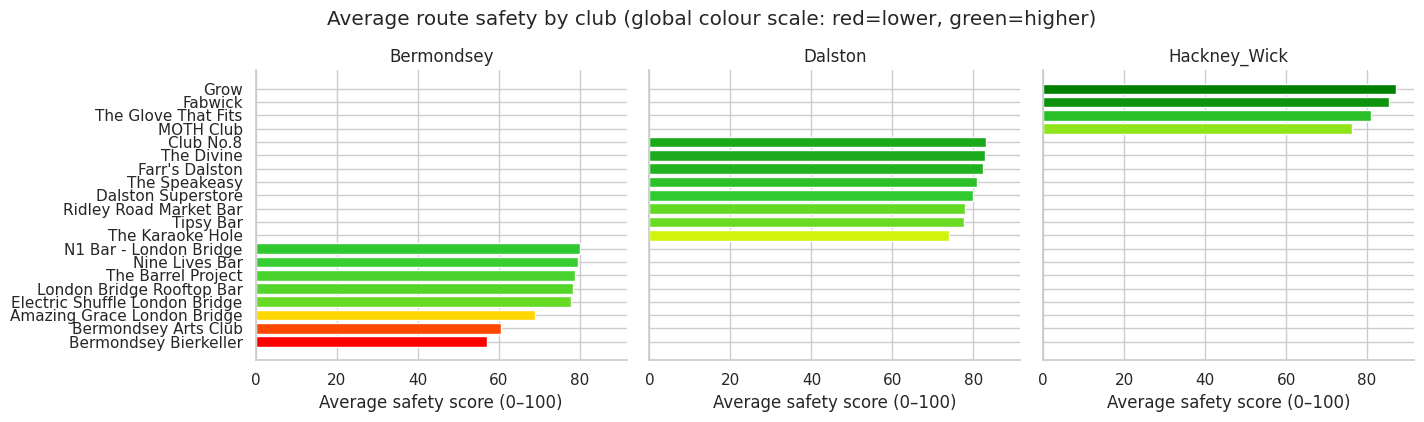

In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

# 1) Combine your club_tables dict into one dataframe
df_plot = pd.concat(
    [t.assign(area=area) for area, t in club_tables.items()],
    ignore_index=True
)

# 2) GLOBAL normalisation (same colours across all areas)
global_min = df_plot["mean_safety_score"].min()
global_max = df_plot["mean_safety_score"].max()

df_plot["safety_norm"] = np.where(
    global_max > global_min,
    (df_plot["mean_safety_score"] - global_min) / (global_max - global_min),
    0
)

# 3) Red -> orange -> yellow -> lime -> green gradient
safety_cmap = LinearSegmentedColormap.from_list(
    "safety_scale",
    ["red", "orange", "yellow", "limegreen", "green"]
)

sns.set_theme(style="whitegrid")

# 4) Facet grid
g = sns.FacetGrid(
    df_plot,
    col="area",
    col_wrap=3,
    sharex=True,     # same x-scale helps comparisons
    height=4,
    aspect=1.2
)

def barplot_with_gradient(data, **kwargs):
    ax = plt.gca()

    # Sort so safest at top
    data = data.sort_values("mean_safety_score", ascending=True)

    colors = safety_cmap(data["safety_norm"].values)

    ax.barh(
        y=data["club_name"],
        width=data["mean_safety_score"],
        color=colors
    )

    ax.set_xlabel("Average safety score (0–100)")
    ax.set_ylabel("")

g.map_dataframe(barplot_with_gradient)

g.set_titles("{col_name}")
g.fig.suptitle(
    "Average route safety by club (global colour scale: red=lower, green=higher)",
    y=1.05
)

plt.show()
